# Fixed Income Multi-Factor Model — Backtesting

A single self-contained notebook: **load index data → build factors → combine →
backtest → report**. Run it top to bottom.

## How this notebook is organised

| Step | What it does |
|---|---|
| **0** | Control panel — every setting lives in one cell |
| **1** | Helpers (dates, ranking, missing-value policy) |
| **2** | Load ICE index files → one canonical panel |
| **3** | Derive shared fields, validate the panel |
| **4** | Factor definitions (Value, Momentum, Size, Low-Risk) |
| **5** | Score every factor → rank + quintile |
| **6** | Composite + regime overlay |
| **7** | Backtest: portfolios, benchmark, analytics |
| **8** | Diagnostics: IC / t-stats, transition matrices |
| **9** | Export to Excel |
| **10** | Performance charts |
| **11** | Diagnostic: active **sector** exposure |
| **12** | Diagnostic: active **rating** exposure |
| **13** | Export historical screens (separate workbook) |
| **14** | Run summary |

## Three principles it follows

1. **Raw column names are mapped once**, in Step 2, to canonical names. Nothing
   after that refers to a vendor header, so a vendor rename is a one-line fix.
2. **Factors are plug-and-play.** A factor is a function plus one entry in the
   `FACTORS` dict (Step 4). Adding one requires no changes to the ranking,
   composite, backtest or reporting code.
3. **Every methodology choice is an explicit setting**, not a line buried in a
   loop. See the methodology block in Step 0.


---
# Step 0 — Control panel

Everything configurable lives here. No settings are hidden further down.

In [41]:
import os
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

# ── Regime overlay (time-varying weights from the trade file) ───────────────
USE_REGIME_OVERLAY = True            # True requires TRADE_WEIGHTS_FILE
TRADE_WEIGHTS_FILE = r"Trade File Template HY - 33 Mom 33 Value 33 LowRisk.xlsx"
REGIME_VARIANTS = ["YP", "LE"]

# ── Where the data lives ────────────────────────────────────────────────────
FOLDER_PATH = r"Input Files"          # folder of ICE monthly workbooks
OUTPUT_DIR = r"Output"

# ── Universe & window ───────────────────────────────────────────────────────
INDEX_TYPE = "HPID"                   # 'C0A0' = IG, 'H0A0' = USHY, 'HPID' = EUHY
START_YM, END_YM = (2005, 6), (2026, 10)

# ── Factor weights (composite). Set a weight to 0 to exclude a factor. ──────
FACTOR_WEIGHTS = {
    "momentum": 1 / 4,
    "value":    1 / 4,
    "low_risk": 1 / 4,
    "size":     1 / 4,
}

# ── Backtest ────────────────────────────────────────────────────────────────
N_BUCKETS = 5                         # 5 = quintiles
PORTFOLIO_WEIGHTING = "equal"         # 'equal' | 'mktcap'
PERIODS_PER_YEAR = 12
LONG_BUCKET, SHORT_BUCKET = 1, 5      # for the long/short spread

# ── Historical screens (separate workbook, one sheet per month) ───────────
EXPORT_SCREENS = True
CUTOFF_DATE = pd.Timestamp("2005-12-31")   # only export months AFTER this
EXPORT_DATES = None                        # None = all months after the cutoff
SCREEN_LAST_N_MONTHS = 2 #255                 # None = every month (large file!)

# ── Diagnostic exposure charts ──────────────────────────────────
DIAG_SIGNAL = "composite_YP"          # which signal's buckets to analyse
DIAG_QUINTILES = [1, 5]               # buckets to chart
DIAG_TOP_N = 7                        # how many categories to show

# ── Faster Notebook Performance ─────────────────────────────────────────────────────────────
USE_CACHE = False                      # cache the prepared panel to disk
CACHE_DIR = ".cache"
USE_SYNTHETIC = False                 # True = generated data, no files needed

# ── Derived ─────────────────────────────────────────────────────────────────
INDEX_SUFFIX = (
    "IG" if INDEX_TYPE == "C0A0"
    else "USHY" if INDEX_TYPE == "H0A0"
    else "EUHY" if INDEX_TYPE == "HPID"
    else INDEX_TYPE
)
Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)

print(f"Universe        : {INDEX_TYPE} ({INDEX_SUFFIX})")
print(f"Window          : {START_YM[0]}-{START_YM[1]:02d} → {END_YM[0]}-{END_YM[1]:02d}")
print(f"Factor weights  : { {k: round(v, 4) for k, v in FACTOR_WEIGHTS.items() if v} }")


Universe        : HPID (EUHY)
Window          : 2005-06 → 2026-10
Factor weights  : {'momentum': 0.25, 'value': 0.25, 'low_risk': 0.25, 'size': 0.25}


---
# Step 1 — Helpers

Small utilities used throughout: month-end dates, cross-sectional ranking, and
the missing-value policy.

**On ranking direction.** Every factor declares whether a high or a low raw value
is "good". Ranking then follows one rule: **bucket 1 is always the most
attractive**, and a *lower* percentile rank is always better. That single
convention lets the composite simply add weighted ranks together.

In [42]:
def month_end_dates(start_ym, end_ym):
    """Month-end dates. ICE always dates February as the 28th."""
    days = {1: 31, 2: 28, 3: 31, 4: 30, 5: 31, 6: 30,
            7: 31, 8: 31, 9: 30, 10: 31, 11: 30, 12: 31}
    out, (y, m) = [], start_ym
    while (y, m) <= end_ym:
        out.append(pd.Timestamp(year=y, month=m, day=days[m]))
        m += 1
        if m > 12:
            y, m = y + 1, 1
    return out


def buckets(values: pd.Series, n: int, higher_is_better: bool) -> pd.Series:
    """Split into n buckets, 1 = best. NaN-safe, tolerant of duplicate edges."""
    clean = values.dropna()
    if clean.empty or clean.nunique() < 2:
        return pd.Series(np.nan, index=values.index)
    ordered = -clean if higher_is_better else clean
    try:
        b = pd.qcut(ordered, n, labels=False, duplicates="drop") + 1
    except ValueError:
        return pd.Series(np.nan, index=values.index)
    return pd.Series(b, index=clean.index).reindex(values.index)


def pct_rank(df, col, by, higher_is_better: bool) -> pd.Series:
    """Percentile rank in [0,1] within each group. Lower = better, always."""
    return df.groupby(by)[col].rank(pct=True, ascending=not higher_is_better)


def fill_missing(df, cols, by, how: str):
    """Apply a missing-value policy to `cols`."""
    if how == "none":
        return df
    for c in cols:
        if how == "group_median":
            df[c] = df.groupby(by)[c].transform(lambda s: s.fillna(s.median()))
        elif how == "group_then_global":
            df[c] = df[c].fillna(df.groupby(by)[c].transform("median"))
            df[c] = df[c].fillna(df[c].median())
        else:
            raise ValueError(f"unknown fill policy: {how}")
    return df


def fit_ols(X: pd.DataFrame, y: pd.Series):
    """Least-squares fit. Returns fitted values (numpy — no statsmodels needed)."""
    Xv, yv = X.to_numpy(float), y.to_numpy(float)
    beta, *_ = np.linalg.lstsq(Xv, yv, rcond=None)
    return pd.Series(Xv @ beta, index=X.index), beta


DATES = month_end_dates(START_YM, END_YM)
print(f"{len(DATES)} month-ends: {DATES[0]:%Y-%m-%d} → {DATES[-1]:%Y-%m-%d}")

257 month-ends: 2005-06-30 → 2026-10-31


---
# Step 2 — Load the index data

Each ICE workbook holds one month, in a sheet named by index and date. We read
each file, **rename raw columns to canonical names once**, and stack them.

Canonical names used from here on:

| Canonical | Raw ICE header |
|---|---|
| `date` | (from the filename) |
| `bond_id` | `ISIN number` |
| `issuer` | `Ticker` |
| `rating` | `Rating` |
| `oas` | `OAS` |
| `mkt_weight` | `% Mkt Value` |
| `excess_return` | `Excess Return % MTD` |
| `maturity_date` | `Maturity Date` |
| `sector_l1..l4` | `Industry Lvl 1..4 Desc` |

Missing months are reported and skipped rather than raising, so a gap in the
archive doesn't kill the run.

In [43]:
RAW_TO_CANONICAL = {
    "ISIN number": "bond_id",
    "Cusip": "cusip",
    "Description": "description",
    "Ticker": "issuer",
    "ISO Currency Code": "currency",
    "Rating": "rating",
    "Maturity Date": "maturity_date",
    "OAS": "oas",
    "Yield to Worst (s.a.)": "ytw",
    "Yield to Maturity (s.a.)": "ytm",
    "Price": "price",
    "Mod. Dur to Worst (s.a.)": "mod_dur_worst",
    "Effective Duration": "eff_dur",
    "Effective Convexity": "eff_convexity",
    "% Mkt Value": "mkt_weight",
    "Excess Return % MTD": "excess_return",
    "Industry Lvl 1 Desc": "sector_l1",
    "Industry Lvl 2 Desc": "sector_l2",
    "Industry Lvl 3 Desc": "sector_l3",
    "Industry Lvl 4 Desc": "sector_l4",
}

REQUIRED = ["date", "bond_id", "issuer", "rating", "oas",
            "mkt_weight", "excess_return", "maturity_date"]
SHEET_PREFIX = {"C0A0": "C0A0", "H0A0": "H0A0", "HPID": "HPID"}

_C0A0_SHEETS = {
    "01-31": "C0A03101 ", "02-28": "C0A02802 ", "03-31": "C0A03103 ",
    "04-30": "C0A03004 ", "05-31": "C0A03105 ", "06-30": "C0A03006 ",
    "07-31": "C0A03107 ", "08-31": "C0A03108 ", "09-30": "C0A03009 ",
    "10-31": "C0A03110 ", "11-30": "C0A03011 ", "12-31": "C0A03112 "
}

_H0A0_SHEETS = {
    "01-31": "H0A00131 ", "02-28": "H0A00228 ", "03-31": "H0A00331 ",
    "04-30": "H0A00430 ", "05-31": "H0A00531 ", "06-30": "H0A00630 ",
    "07-31": "H0A00731 ", "08-31": "H0A00831 ", "09-30": "H0A00930 ",
    "10-31": "H0A01031 ", "11-30": "H0A01130 ", "12-31": "H0A01231 "
}

_HPID_SHEETS = {
    "01-31": "HPID0131 ", "02-28": "HPID0228 ", "03-31": "HPID0331 ",
    "04-30": "HPID0430 ", "05-31": "HPID0531 ", "06-30": "HPID0630 ",
    "07-31": "HPID0731 ", "08-31": "HPID0831 ", "09-30": "HPID0930 ",
    "10-31": "HPID1031 ", "11-30": "HPID1130 ", "12-31": "HPID1231 "
}

SHEET_MAP = {"C0A0": _C0A0_SHEETS, "H0A0": _H0A0_SHEETS, "HPID": _HPID_SHEETS}


def ice_filename(d: pd.Timestamp, index_type: str) -> str:
    fmt = "%d%m%Y" if index_type == "C0A0" else "%m%d%Y"
    return f"{index_type}-{d.strftime(fmt)}.xlsx"


def _find_header_row(raw: pd.DataFrame, max_scan: int = 15):
    """Locate the real column-header row (handles HPID's title banner)."""
    for i in range(min(max_scan, len(raw))):
        vals = [str(x).strip() for x in raw.iloc[i].tolist() if pd.notna(x)]
        if "Cusip" in vals and "ISIN number" in vals:
            return i
    return None


def load_month(d: pd.Timestamp, index_type: str, folder: str):
    """Read one ICE month. Returns None (with a note) if unavailable.

    Handles HPID files (title banner on row 1 + disclosure footer) and
    cleans trailing blank/footer rows from H0A0 / C0A0 files.
    """
    sheet = SHEET_MAP[index_type].get(d.strftime("%m-%d"))
    if sheet is None:
        return None, f"no sheet mapping for {d:%Y-%m-%d}"
    path = os.path.join(folder, ice_filename(d, index_type))
    try:
        raw = pd.read_excel(path, sheet_name=sheet, header=None)
    except Exception as exc:
        return None, f"{os.path.basename(path)}: {exc}"

    # Find the header row dynamically (skips HPID's "HPID for .." banner).
    header_idx = _find_header_row(raw)
    if header_idx is None:
        return None, f"{os.path.basename(path)}: header row not found"

    df = raw.iloc[header_idx + 1:].copy()
    df.columns = [str(c).strip() if c is not None else c
                  for c in raw.iloc[header_idx]]
    df = df.rename(columns=RAW_TO_CANONICAL)
    df = df.loc[:, ~df.columns.duplicated()]

    # Drop disclosure/disclaimer + trailing blank rows: keep rows with a
    # valid bond_id (footer text and blank rows have a null ISIN).
    if "bond_id" in df.columns:
        df = df[df["bond_id"].notna()]
        df = df[df["bond_id"].astype(str).str.strip() != ""]
    df = df.dropna(how="all")

    df["date"] = d
    return df.reset_index(drop=True), None


def load_index(dates, index_type, folder, verbose_every=24):
    frames, problems = [], []
    for i, d in enumerate(dates):
        df, err = load_month(d, index_type, folder)
        if err:
            problems.append(err)
        else:
            frames.append(df)
        if verbose_every and i % verbose_every == 0:
            print(f"  ... {d:%Y-%m}  ({len(frames)} loaded)")
    if not frames:
        raise FileNotFoundError(
            f"No {index_type} files loaded from '{folder}'. Check FOLDER_PATH."
        )
    panel = pd.concat(frames, ignore_index=True)
    # ICE quotes excess return in percent; convert to a decimal.
    panel["excess_return"] = pd.to_numeric(panel["excess_return"], errors="coerce") / 100
    return panel, problems


cache_file = Path(CACHE_DIR) / f"panel_{INDEX_TYPE}_{START_YM[0]}{START_YM[1]:02d}_{END_YM[0]}{END_YM[1]:02d}.pkl"

if USE_CACHE and cache_file.exists():
    print(f"Loading cached panel: {cache_file}")
    raw_panel, problems = pd.read_pickle(cache_file), []
else:
    print(f"Reading {INDEX_TYPE} files from: {FOLDER_PATH}")
    raw_panel, problems = load_index(DATES, INDEX_TYPE, FOLDER_PATH)
    if USE_CACHE:
        cache_file.parent.mkdir(parents=True, exist_ok=True)
        raw_panel.to_pickle(cache_file)
        print(f"Cached → {cache_file}")

print(f"\nLoaded {raw_panel.shape[0]:,} rows × {raw_panel.shape[1]} cols, "
      f"{raw_panel['date'].nunique()} months")
if problems:
    print(f"\n{len(problems)} month(s) unavailable — first few:")
    for p in problems[:5]:
        print("   ", p)

Reading HPID files from: Input Files
  ... 2005-06  (1 loaded)
  ... 2007-06  (25 loaded)
  ... 2009-06  (49 loaded)
  ... 2011-06  (73 loaded)
  ... 2013-06  (97 loaded)
  ... 2015-06  (121 loaded)
  ... 2017-06  (145 loaded)
  ... 2019-06  (169 loaded)
  ... 2021-06  (193 loaded)
  ... 2023-06  (217 loaded)
  ... 2025-06  (241 loaded)

Loaded 119,228 rows × 39 cols, 257 months


> **Cache note.** The prepared panel is cached to `.cache/`. That makes repeat
> runs fast, but it also means **edits to the loading code above have no effect
> until you clear it**. Set `USE_CACHE = False` (or delete the folder) while
> changing anything in Step 2.

In [44]:
RAW_TO_CANONICAL = {
    "ISIN number": "bond_id",
    "Cusip": "cusip",
    "Description": "description",
    "Ticker": "issuer",
    "ISO Currency Code": "currency",
    "Rating": "rating",
    "Maturity Date": "maturity_date",
    "OAS": "oas",
    "Yield to Worst (s.a.)": "ytw",
    "Yield to Maturity (s.a.)": "ytm",
    "Price": "price",
    "Mod. Dur to Worst (s.a.)": "mod_dur_worst",
    "Effective Duration": "eff_dur",
    "Effective Convexity": "eff_convexity",
    "% Mkt Value": "mkt_weight",
    "Excess Return % MTD": "excess_return",
    "Industry Lvl 1 Desc": "sector_l1",
    "Industry Lvl 2 Desc": "sector_l2",
    "Industry Lvl 3 Desc": "sector_l3",
    "Industry Lvl 4 Desc": "sector_l4",
}

REQUIRED = ["date", "bond_id", "issuer", "rating", "oas",
            "mkt_weight", "excess_return", "maturity_date"]
SHEET_PREFIX = {"C0A0": "C0A0", "H0A0": "H0A0", "HPID": "HPID"}

_C0A0_SHEETS = {
    "01-31": "C0A03101 ", "02-28": "C0A02802 ", "03-31": "C0A03103 ",
    "04-30": "C0A03004 ", "05-31": "C0A03105 ", "06-30": "C0A03006 ",
    "07-31": "C0A03107 ", "08-31": "C0A03108 ", "09-30": "C0A03009 ",
    "10-31": "C0A03110 ", "11-30": "C0A03011 ", "12-31": "C0A03112 "
}

_H0A0_SHEETS = {
    "01-31": "H0A00131 ", "02-28": "H0A00228 ", "03-31": "H0A00331 ",
    "04-30": "H0A00430 ", "05-31": "H0A00531 ", "06-30": "H0A00630 ",
    "07-31": "H0A00731 ", "08-31": "H0A00831 ", "09-30": "H0A00930 ",
    "10-31": "H0A01031 ", "11-30": "H0A01130 ", "12-31": "H0A01231 "
}

_HPID_SHEETS = {
    "01-31": "HPID0131 ", "02-28": "HPID0228 ", "03-31": "HPID0331 ",
    "04-30": "HPID0430 ", "05-31": "HPID0531 ", "06-30": "HPID0630 ",
    "07-31": "HPID0731 ", "08-31": "HPID0831 ", "09-30": "HPID0930 ",
    "10-31": "HPID1031 ", "11-30": "HPID1130 ", "12-31": "HPID1231 "
}

SHEET_MAP = {"C0A0": _C0A0_SHEETS, "H0A0": _H0A0_SHEETS, "HPID": _HPID_SHEETS}


def ice_filename(d: pd.Timestamp, index_type: str) -> str:
    fmt = "%d%m%Y" if index_type == "C0A0" else "%m%d%Y"
    return f"{index_type}-{d.strftime(fmt)}.xlsx"


def _find_header_row(raw: pd.DataFrame, max_scan: int = 15):
    """Locate the real column-header row (handles HPID's title banner)."""
    for i in range(min(max_scan, len(raw))):
        vals = [str(x).strip() for x in raw.iloc[i].tolist() if pd.notna(x)]
        if "Cusip" in vals and "ISIN number" in vals:
            return i
    return None


def load_month(d: pd.Timestamp, index_type: str, folder: str):
    """Read one ICE month. Returns None (with a note) if unavailable.

    Handles HPID files (title banner on row 1 + disclosure footer) and
    cleans trailing blank/footer rows from H0A0 / C0A0 files.
    """
    sheet = SHEET_MAP[index_type].get(d.strftime("%m-%d"))
    if sheet is None:
        return None, f"no sheet mapping for {d:%Y-%m-%d}"
    path = os.path.join(folder, ice_filename(d, index_type))
    try:
        raw = pd.read_excel(path, sheet_name=sheet, header=None)
    except Exception as exc:
        return None, f"{os.path.basename(path)}: {exc}"

    # Find the header row dynamically (skips HPID's "HPID for .." banner).
    header_idx = _find_header_row(raw)
    if header_idx is None:
        return None, f"{os.path.basename(path)}: header row not found"

    df = raw.iloc[header_idx + 1:].copy()
    df.columns = [str(c).strip() if c is not None else c
                  for c in raw.iloc[header_idx]]
    df = df.rename(columns=RAW_TO_CANONICAL)
    df = df.loc[:, ~df.columns.duplicated()]

    # Drop disclosure/disclaimer + trailing blank rows: keep rows with a
    # valid bond_id (footer text and blank rows have a null ISIN).
    if "bond_id" in df.columns:
        df = df[df["bond_id"].notna()]
        df = df[df["bond_id"].astype(str).str.strip() != ""]
    df = df.dropna(how="all")

    df["date"] = d
    return df.reset_index(drop=True), None


def load_index(dates, index_type, folder, verbose_every=24):
    frames, problems = [], []
    for i, d in enumerate(dates):
        df, err = load_month(d, index_type, folder)
        if err:
            problems.append(err)
        else:
            frames.append(df)
        if verbose_every and i % verbose_every == 0:
            print(f"  ... {d:%Y-%m}  ({len(frames)} loaded)")
    if not frames:
        raise FileNotFoundError(
            f"No {index_type} files loaded from '{folder}'. Check FOLDER_PATH."
        )
    panel = pd.concat(frames, ignore_index=True)
    # ICE quotes excess return in percent; convert to a decimal.
    panel["excess_return"] = pd.to_numeric(panel["excess_return"], errors="coerce") / 100
    return panel, problems


cache_file = Path(CACHE_DIR) / f"panel_{INDEX_TYPE}_{START_YM[0]}{START_YM[1]:02d}_{END_YM[0]}{END_YM[1]:02d}.pkl"

if USE_CACHE and cache_file.exists():
    print(f"Loading cached panel: {cache_file}")
    raw_panel, problems = pd.read_pickle(cache_file), []
else:
    print(f"Reading {INDEX_TYPE} files from: {FOLDER_PATH}")
    raw_panel, problems = load_index(DATES, INDEX_TYPE, FOLDER_PATH)
    if USE_CACHE:
        cache_file.parent.mkdir(parents=True, exist_ok=True)
        raw_panel.to_pickle(cache_file)
        print(f"Cached → {cache_file}")

print(f"\nLoaded {raw_panel.shape[0]:,} rows × {raw_panel.shape[1]} cols, "
      f"{raw_panel['date'].nunique()} months")
if problems:
    print(f"\n{len(problems)} month(s) unavailable — first few:")
    for p in problems[:5]:
        print("   ", p)

Reading HPID files from: Input Files
  ... 2005-06  (1 loaded)
  ... 2007-06  (25 loaded)
  ... 2009-06  (49 loaded)
  ... 2011-06  (73 loaded)
  ... 2013-06  (97 loaded)
  ... 2015-06  (121 loaded)
  ... 2017-06  (145 loaded)
  ... 2019-06  (169 loaded)
  ... 2021-06  (193 loaded)
  ... 2023-06  (217 loaded)
  ... 2025-06  (241 loaded)

Loaded 119,228 rows × 39 cols, 257 months


---
# Step 3 — Prepare and validate the panel

Coerce types, derive shared fields, and check the panel before any factor runs.
Validating here means a data problem surfaces as a clear message rather than a
confusing error deep inside a factor.

In [45]:
def prepare(panel: pd.DataFrame) -> pd.DataFrame:
    df = panel.copy()
    df["date"] = pd.to_datetime(df["date"])
    df["maturity_date"] = pd.to_datetime(df["maturity_date"], errors="coerce")
    for c in ["oas", "ytw", "ytm", "price", "mkt_weight",
              "excess_return", "mod_dur_worst", "eff_dur"]:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")
    df["rating"] = df["rating"].astype(str).str.strip().str.upper()
    df["issuer"] = df["issuer"].astype(str)
    # Shared derived field: time to maturity in years.
    df["maturity_years"] = (df["maturity_date"] - df["date"]).dt.days / 365.25
    return df.sort_values(["bond_id", "date"]).reset_index(drop=True)


def validate(df: pd.DataFrame) -> None:
    missing = [c for c in REQUIRED if c not in df.columns]
    if missing:
        raise ValueError(f"Panel is missing required columns: {missing}")
    if df["date"].isna().any():
        raise ValueError("'date' contains nulls")
    if df["bond_id"].isna().all():
        raise ValueError("'bond_id' is entirely null")
    print("Schema OK — all required columns present.\n")
    counts = df.groupby("date").size()
    print(f"Rows          : {len(df):,}")
    print(f"Months        : {df['date'].nunique()}  "
          f"({df['date'].min():%Y-%m-%d} → {df['date'].max():%Y-%m-%d})")
    print(f"Unique bonds  : {df['bond_id'].nunique():,}")
    print(f"Issuers       : {df['issuer'].nunique():,}")
    print(f"Bonds / month : min {counts.min():,}  median {int(counts.median()):,}  max {counts.max():,}")
    nulls = df[REQUIRED].isna().sum()
    nulls = nulls[nulls > 0]
    print("\nNulls in required columns:")
    print("  none" if nulls.empty else nulls.to_string())


panel = prepare(raw_panel)
validate(panel)

Schema OK — all required columns present.

Rows          : 119,228
Months        : 257  (2005-06-30 → 2026-10-31)
Unique bonds  : 3,210
Issuers       : 1,158
Bonds / month : min 169  median 505  max 766

Nulls in required columns:
excess_return    2440


---
# Step 4 — Factor definitions

Each factor is **one function** returning a raw score per row, plus **one entry**
in the `FACTORS` dict declaring:

* `func` — the scoring function
* `higher_is_better` — ranking direction
* `fill` — missing-value policy for this factor
* `is_rank` — `True` if the function already returns a 0–1 rank (Low-Risk does)

**To add a factor:** write the function, add an entry, give it a weight in
Step 0. Nothing else in the notebook changes.

### The four factors

**Value** — cross-sectional regression of OAS on maturity, 3-month OAS change,
rating and sector dummies. The signal is the % deviation of actual from fitted:

$$\text{deviation}_{i,t} = \frac{y_{i,t}-\hat{y}_{i,t}}{\hat{y}_{i,t}}\times 100$$

Positive ⇒ trades wider than the model implies ⇒ **cheap** ⇒ attractive.

**Momentum** — compounded excess return over the trailing 6 months, **lagged one
month** so the current month never leaks into its own signal:

$$\text{mom}_{i,t}=\prod_{k=1}^{6}\left(1+r_{i,t-k}\right)-1$$

**Size** — total index weight of the issuer. Smaller issuers score better.

**Low-Risk** — 50/50 blend of maturity rank and rating rank; shorter and higher
quality is safer. Already a rank, so `is_rank = True`.

In [46]:
IG_RATING_RANK = {"AAA": .1, "AA1": .2, "AA2": .3, "AA3": .4, "A1": .5,
                  "A2": .6, "A3": .7, "BBB1": .8, "BBB2": .9, "BBB3": 1.0}
HY_RATING_RANK = {"BBB3": .0833, "BB1": .1667, "BB2": .25, "BB3": .3333,
                  "B1": .4167, "B2": .5, "B3": .5833, "CCC1": .6667,
                  "CCC2": .75, "CCC3": .8333, "CC": .9167, "C": 1.0}


HY_INDICES = {"H0A0", "HPID"}
RATING_RANK = HY_RATING_RANK if INDEX_TYPE in HY_INDICES else IG_RATING_RANK

BROAD_RATING = {**{r: "AAA" for r in ["AAA"]},
                **{f"AA{i}": "AA" for i in "123"}, **{f"A{i}": "A" for i in "123"},
                **{f"BBB{i}": "BBB" for i in "123"}, **{f"BB{i}": "BB" for i in "123"},
                **{f"B{i}": "B" for i in "123"}, **{f"CCC{i}": "CCC" for i in "123"},
                "CC": "CC", "C": "C"}
RATING_ORDER = ["AAA", "AA", "A", "BBB", "BB", "B", "CCC", "CC", "C"]


# ── Value ───────────────────────────────────────────────────────────────────
def cross_sectional_oas_regression(df_date, reg_cols, dummy_cols, dep="oas"):
    """Fit OAS on characteristics for ONE date. Returns % deviation per bond."""
    parts = [df_date[reg_cols]]
    for c in dummy_cols:
        parts.append(pd.get_dummies(df_date[c], prefix=c))
    X = pd.concat(parts, axis=1).astype(float)
    X.insert(0, "const", 1.0)
    y = df_date[dep].astype(float)

    ok = (X.notnull().all(axis=1) & ~np.isinf(X).any(axis=1)
          & y.notnull() & ~np.isinf(y))
    X, y = X.loc[ok], y.loc[ok]
    if len(X) <= X.shape[1]:            # under-determined
        return None
    fitted, _ = fit_ols(X, y)
    return ((y - fitted) / fitted) * 100
    #return ((y - fitted) / abs(fitted)) * 100



def factor_value(df, oas_change_months=3):
    d = df.sort_values(["bond_id", "date"]).copy()
    d["_oas_chg"] = d.groupby("bond_id")["oas"].diff(oas_change_months)
    dummies = [c for c in ["rating", "sector_l3"] if c in d.columns]
    pieces = []
    for _, slice_ in d.groupby("date"):
        res = cross_sectional_oas_regression(
            df_date=slice_, reg_cols=["maturity_years", "_oas_chg"], dummy_cols=dummies, dep="oas")
        if res is not None:
            pieces.append(res)
    if not pieces:
        return pd.Series(np.nan, index=df.index)
    return pd.concat(pieces).reindex(df.index)


# ── Momentum ────────────────────────────────────────────────────────────────
def factor_momentum(df, window=6):
    d = df.sort_values(["bond_id", "date"])
    mom = (d.groupby("bond_id")["excess_return"]
             .transform(lambda x: (1 + x.shift(1))
                        .rolling(window).apply(np.prod, raw=True) - 1))
    return mom.reindex(df.index)


# ── Size ────────────────────────────────────────────────────────────────────
def factor_size(df):
    return df.assign(_w=pd.to_numeric(df["mkt_weight"], errors="coerce")) \
             .groupby(["date", "issuer"], dropna=False)["_w"].transform("sum")


# ── Low-Risk ────────────────────────────────────────────────────────────────
def factor_low_risk(df, maturity_weight=.5, rating_weight=.5):
    mat_rank = pct_rank(df, "maturity_years", "date", higher_is_better=False)
    rat_rank = df["rating"].map(RATING_RANK)
    blend = pd.DataFrame({"m": mat_rank, "r": rat_rank, "date": df["date"]})
    blend = fill_missing(blend, ["m", "r"], "date", "group_median")
    return maturity_weight * blend["m"] + rating_weight * blend["r"]


# ── The registry ────────────────────────────────────────────────────────────
FACTORS = {
    "value":    dict(func=factor_value,    higher_is_better=True,
                     fill="group_median", is_rank=False,
                     label="Value (cheap vs fitted OAS)"),
    "momentum": dict(func=factor_momentum, higher_is_better=True,
                     fill="group_median", is_rank=False,
                     label="6m momentum (lagged)"),
    "size":     dict(func=factor_size,     higher_is_better=False,
                     fill="group_median", is_rank=False,
                     label="Issuer index weight"),
    "low_risk": dict(func=factor_low_risk, higher_is_better=False,
                     fill="group_median", is_rank=True,
                     label="Maturity + rating blend"),
}

ACTIVE = [f for f, w in FACTOR_WEIGHTS.items() if f in FACTORS]
print(f"Rating scheme : {INDEX_SUFFIX} ({len(RATING_RANK)} notches)\n")
print(f"{'factor':10} {'weight':>8}  {'better':<7} {'fill':<13} label")
print("-" * 78)
for f in ACTIVE:
    s = FACTORS[f]
    print(f"{f:10} {FACTOR_WEIGHTS[f]:>8.3f}  "
          f"{'high' if s['higher_is_better'] else 'low':<7} {s['fill']:<13} {s['label']}")

Rating scheme : EUHY (12 notches)

factor       weight  better  fill          label
------------------------------------------------------------------------------
momentum      0.250  high    group_median  6m momentum (lagged)
value         0.250  high    group_median  Value (cheap vs fitted OAS)
low_risk      0.250  low     group_median  Maturity + rating blend
size          0.250  low     group_median  Issuer index weight


---
# Step 5 — Score every factor

One generic loop turns each factor into three columns:

* `<factor>` — the raw score
* `<factor>_rank` — percentile within the month (**lower = better**)
* `<factor>_quintile` — bucket 1…5 (**1 = best**)

Because this loop is factor-agnostic, a new factor is picked up automatically.

The summary shows `first_valid` — the first month a factor produces a score.
Value needs 3 months of OAS history and Momentum needs 7, so they start later
than Size and Low-Risk. That is expected, not a bug.

In [47]:
def score_factor(df, name, spec, n_buckets):
    """Add <name>, <name>_rank and <name>_quintile to df."""
    df = df.copy()
    df[name] = spec["func"](df)
    df = fill_missing(df, [name], "date", spec["fill"])

    if spec["is_rank"]:
        df[f"{name}_rank"] = df[name]
        higher = False                      # already lower-is-better
    else:
        df[f"{name}_rank"] = pct_rank(df, name, "date", spec["higher_is_better"])
        higher = spec["higher_is_better"]

    df[f"{name}_quintile"] = df.groupby("date")[name].transform(
        lambda s: buckets(s, n_buckets, higher))
    return df


for name in ACTIVE:
    panel = score_factor(panel, name, FACTORS[name], N_BUCKETS)
    print(f"  scored {name}")

print(f"\n{'factor':10} {'scored':>9} {'bucketed':>9} {'missing':>9}  first_valid")
print("-" * 62)
for name in ACTIVE:
    v, q = panel[name], panel[f"{name}_quintile"]
    first = panel.loc[v.notna(), "date"].min()
    print(f"{name:10} {v.notna().sum():>9,} {q.notna().sum():>9,} "
          f"{v.isna().sum():>9,}  {first:%Y-%m-%d}")

c:\Users\feme\OneDrive - Barings\feme\python_source_code\.venv\Lib\site-packages\numpy\lib\nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
c:\Users\feme\OneDrive - Barings\feme\python_source_code\.venv\Lib\site-packages\numpy\lib\nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
c:\Users\feme\OneDrive - Barings\feme\python_source_code\.venv\Lib\site-packages\numpy\lib\nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
c:\Users\feme\OneDrive - Barings\feme\python_source_code\.venv\Lib\site-packages\numpy\lib\nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
c:\Users\feme\OneDrive - Barings\feme\python_source_code\.venv\Lib\site-packages\numpy\lib\nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis

  scored momentum


c:\Users\feme\OneDrive - Barings\feme\python_source_code\.venv\Lib\site-packages\numpy\lib\nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
c:\Users\feme\OneDrive - Barings\feme\python_source_code\.venv\Lib\site-packages\numpy\lib\nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
c:\Users\feme\OneDrive - Barings\feme\python_source_code\.venv\Lib\site-packages\numpy\lib\nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


  scored value
  scored low_risk
  scored size

factor        scored  bucketed   missing  first_valid
--------------------------------------------------------------
momentum     117,938   117,938     1,290  2005-12-31
value        118,584   118,584       644  2005-09-30
low_risk     119,228   119,228         0  2005-06-30
size         119,228   119,228         0  2005-06-30


---
# Step 6 — Composite signal

The composite is the weighted sum of factor **ranks**. Since every rank is
oriented lower-is-better, a low composite rank is attractive, and bucket 1 is the
model's best names.

Ranks are median-filled first so a bond missing one factor still receives a
composite score rather than dropping out entirely.

**Optional regime overlay** — if enabled, factor weights vary month by month
according to the trade-weights file, producing additional `composite_YP` /
`composite_LE` signals alongside the fixed-weight composite.

In [48]:
rank_cols = [f"{f}_rank" for f in ACTIVE if FACTOR_WEIGHTS.get(f, 0)]
panel = fill_missing(panel, rank_cols, "date", "group_then_global")

panel["composite_rank"] = sum(
    panel[f"{f}_rank"] * w for f, w in FACTOR_WEIGHTS.items() if w and f in FACTORS
)
panel["composite_quintile"] = panel.groupby("date")["composite_rank"].transform(
    lambda s: buckets(s, N_BUCKETS, higher_is_better=False))

SIGNALS = {f: (f"{f}_rank", f"{f}_quintile") for f in ACTIVE}
SIGNALS["composite"] = ("composite_rank", "composite_quintile")

# ── Optional: time-varying regime weights ───────────────────────────────────
if USE_REGIME_OVERLAY:
    TRADE_FACTOR_MAP = {
        "Value_Rating_Maturity_OAS": "value",
        "6_month_momentum": "momentum",
        "Company_index_weight": "size",
        "low_risk_paper": "low_risk",
    }

    def to_month_end(d):
        d = pd.Timestamp(d)
        return (pd.Timestamp(d.year, 2, 28) if d.month == 2
                else (d + pd.offsets.MonthEnd(0)).normalize())

    tw = pd.read_excel(TRADE_WEIGHTS_FILE, sheet_name="Trading Model Results")
    tw["Factor"] = tw["Factor"].replace(TRADE_FACTOR_MAP)
    tw["TradeDate"] = tw["TradeDate"].apply(to_month_end)

    for variant in REGIME_VARIANTS:
        col = f"TradeAmount_{variant}"
        if col not in tw.columns:
            print(f"  skipping {variant} — '{col}' not in the trade file")
            continue
        wide = tw.pivot_table(index="TradeDate", columns="Factor",
                              values=col, aggfunc="first")
        merged = panel[["date"]].merge(wide, left_on="date",
                                       right_index=True, how="left")
        total = None
        for f in ACTIVE:
            if f in wide.columns:
                part = merged[f].to_numpy() * panel[f"{f}_rank"].to_numpy()
                total = part if total is None else total + part
        rk, qk = f"composite_{variant}_rank", f"composite_{variant}_quintile"
        panel[rk] = total
        panel[qk] = panel.groupby("date")[rk].transform(
            lambda s: buckets(s, N_BUCKETS, higher_is_better=False))
        SIGNALS[f"composite_{variant}"] = (rk, qk)
        print(f"  built composite_{variant}")

print("Signals available for backtesting:")
for s in SIGNALS:
    print("   ", s)

  built composite_YP
  built composite_LE
Signals available for backtesting:
    momentum
    value
    low_risk
    size
    composite
    composite_YP
    composite_LE


---
# Step 7 — Backtest

### The timing convention, stated plainly

A portfolio is formed at month **t** using data known at **t**, and earns month
**t+1**'s return. So each row is stamped with its *formation* date and carries
the *next* month's return. This is what prevents look-ahead bias.

**The benchmark uses the same convention**: index weights known at *t* are
applied to *t+1* returns, so it covers the same holding period the portfolios
earn and is built only from weights fixed before that period begins. Month-end
index weights already reflect that month's return, so weighting by them would
overstate the benchmark and understate alpha by the same amount.

Bonds that leave the index (mature, are called, downgraded out or default) have
no following-month return and are excluded from that month's basket rather than
carried at 0%.


In [49]:
def attach_next_month_return(df):
    """Stamp each row with the return earned over the FOLLOWING month."""
    d = df.copy()
    d["_ym"] = d["date"].dt.to_period("M")
    nxt = d[["bond_id", "_ym", "excess_return"]].rename(
        columns={"_ym": "_prev", "excess_return": "next_month_return"})
    nxt["_prev"] = nxt["_prev"] - 1          # shift back so it joins on t
    return d.merge(nxt, left_on=["bond_id", "_ym"],
                   right_on=["bond_id", "_prev"], how="left")


def benchmark_series(df_next):
    """Cap-weighted index return, stamped to match the portfolios.

    Uses index weights known at t applied to month t+1 returns, so the benchmark
    covers the same holding period as the portfolios and is built only from
    weights fixed before the return period begins.
    """
    d = df_next[df_next["next_month_return"].notna()].copy()
    d["mkt_weight"] = pd.to_numeric(d["mkt_weight"], errors="coerce")

    def wavg(g):
        w = g["mkt_weight"].fillna(0)
        return (g["next_month_return"] * w).sum() / w.sum() if w.sum() else np.nan

    return d.groupby("date").apply(wavg).rename("benchmark")


def bucket_returns(df_next, quintile_col, weighting):
    """date × bucket table of portfolio returns, plus Combined.

    Bonds that leave the index have no following-month return and are excluded
    from that month's basket, rather than being carried at 0%.
    """
    d = df_next.dropna(subset=[quintile_col, "next_month_return"]).copy()
    d["_r"] = d["next_month_return"]

    if weighting == "mktcap":
        def wavg(g):
            w = pd.to_numeric(g["mkt_weight"], errors="coerce").fillna(0)
            return (g["_r"] * w).sum() / w.sum() if w.sum() else np.nan
        avg = (d.groupby(["date", quintile_col]).apply(wavg)
                 .reset_index(name="_r"))
    else:
        avg = d.groupby(["date", quintile_col])["_r"].mean().reset_index()

    pivot = avg.pivot(index="date", columns=quintile_col, values="_r")
    pivot["Combined"] = pivot.mean(axis=1)
    return pivot


panel_next = attach_next_month_return(panel)
benchmark = benchmark_series(panel_next)

returns_by_signal = {
    name: bucket_returns(panel_next, qcol, PORTFOLIO_WEIGHTING)
    for name, (_, qcol) in SIGNALS.items()
}

have_next = panel_next["next_month_return"].notna().sum()
print(f"Rows with a next-month return : {have_next:,} of {len(panel_next):,}")
print(f"  (the rest left the index and are excluded from that month's basket)")
print(f"Benchmark months              : {len(benchmark)}\n")
for name, pv in returns_by_signal.items():
    print(f"  {name:16} {len(pv):>4} months   "
          f"Q{LONG_BUCKET} mean {pv.get(LONG_BUCKET, pd.Series(dtype=float)).mean():+.5f}")

Rows with a next-month return : 115,941 of 119,228
  (the rest left the index and are excluded from that month's basket)
Benchmark months              : 256

  momentum          250 months   Q1 mean +0.00512
  value             253 months   Q1 mean +0.00531
  low_risk          256 months   Q1 mean +0.00267
  size              256 months   Q1 mean +0.00502
  composite         256 months   Q1 mean +0.00490
  composite_YP      256 months   Q1 mean +0.00519
  composite_LE      256 months   Q1 mean +0.00496


## Performance analytics

Standard measures per bucket. **Active return** is the portfolio less the
benchmark, so it answers the question that matters: did the signal beat the index?

The **long/short spread** (Q1 − Q5) is the cleanest read on raw signal quality —
it is benchmark-neutral by construction, so it isolates whether the factor ranks
bonds correctly, independent of market direction.

In [50]:
def ann_return(r, ppy=PERIODS_PER_YEAR):
    r = r.dropna()
    return (1 + r).prod() ** (ppy / len(r)) - 1 if len(r) else np.nan


def ann_vol(r, ppy=PERIODS_PER_YEAR):
    return r.std() * np.sqrt(ppy)


def max_drawdown(r):
    cum = (1 + r.dropna()).cumprod()
    return ((cum - cum.cummax()) / cum.cummax()).min() if len(cum) else np.nan


def alpha_beta(port, bench, ppy=PERIODS_PER_YEAR):
    d = pd.DataFrame({"p": port, "b": bench}).dropna()
    if len(d) < 3:
        return np.nan, np.nan
    X = np.column_stack([np.ones(len(d)), d["b"].to_numpy(float)])
    beta, *_ = np.linalg.lstsq(X, d["p"].to_numpy(float), rcond=None)
    return (1 + beta[0]) ** ppy - 1, beta[1]


def capture(port, bench, upside=True):
    mask = bench > 0 if upside else bench < 0
    if mask.sum() < 2:
        return np.nan
    b = ann_return(bench[mask])
    return ann_return(port[mask]) / b if b else np.nan


def turnover(df, quintile_col):
    d = df.sort_values(["bond_id", "date"])
    prev = d.groupby("bond_id")[quintile_col].shift(1)
    valid = prev.notna()
    return (d[quintile_col] != prev)[valid].mean() if valid.any() else np.nan


rows = []
for name, pivot in returns_by_signal.items():
    to = turnover(panel, SIGNALS[name][1])
    for bucket in pivot.columns:
        port = pivot[bucket].dropna()
        common = port.index.intersection(benchmark.index)
        if len(common) < 3:
            continue
        p, b = port.loc[common], benchmark.loc[common]
        a, beta = alpha_beta(p, b)
        rows.append({
            "Signal": name, "Bucket": bucket,
            "Ann Return": ann_return(p), "Ann Vol": ann_vol(p),
            "Ann Active Return": ann_return(p - b),
            "Tracking Error": ann_vol(p - b),
            "Sharpe": ann_return(p) / ann_vol(p) if ann_vol(p) else np.nan,
            "Max Drawdown": max_drawdown(p),
            "Alpha (ann)": a, "Beta": beta,
            "Up Capture": capture(p, b, True),
            "Down Capture": capture(p, b, False),
            "Corr vs BM": p.corr(b), "Turnover": to,
        })
analytics = pd.DataFrame(rows)

# ── Long/short spread (benchmark-neutral view of signal quality) ────────────
ls_rows = []
for name, pivot in returns_by_signal.items():
    if LONG_BUCKET in pivot.columns and SHORT_BUCKET in pivot.columns:
        spread = (pivot[LONG_BUCKET] - pivot[SHORT_BUCKET]).dropna()
        if len(spread) > 2:
            ls_rows.append({
                "Signal": name,
                f"Ann Return (Q{LONG_BUCKET}-Q{SHORT_BUCKET})": ann_return(spread),
                "Ann Vol": ann_vol(spread),
                "Sharpe": ann_return(spread) / ann_vol(spread) if ann_vol(spread) else np.nan,
                "Hit Rate": (spread > 0).mean(),
                "Months": len(spread),
            })
long_short = pd.DataFrame(ls_rows)

print("LONG/SHORT SPREAD — is the signal ranking bonds correctly?")
print(long_short.round(4).to_string(index=False))
print(f"\nANALYTICS — {LONG_BUCKET} = model's best bucket")
print(analytics[analytics["Bucket"] == LONG_BUCKET].round(4).to_string(index=False))

LONG/SHORT SPREAD — is the signal ranking bonds correctly?
      Signal  Ann Return (Q1-Q5)  Ann Vol  Sharpe  Hit Rate  Months
    momentum              0.0322   0.1373  0.2343    0.6477     176
       value              0.0327   0.0767  0.4262    0.5968     253
    low_risk             -0.0299   0.1092 -0.2743    0.4180     256
        size              0.0234   0.1074  0.2182    0.5312     256
   composite              0.0178   0.0555  0.3199    0.6172     256
composite_YP              0.0242   0.0657  0.3683    0.6289     256
composite_LE              0.0281   0.1008  0.2790    0.5156     256

ANALYTICS — 1 = model's best bucket
      Signal Bucket  Ann Return  Ann Vol  Ann Active Return  Tracking Error  Sharpe  Max Drawdown  Alpha (ann)   Beta  Up Capture  Down Capture  Corr vs BM  Turnover
    momentum    1.0      0.0576   0.0999             0.0208          0.0445  0.5770       -0.4279       0.0244 0.9367      1.0979        0.8922      0.8973    0.4224
       value    1.0      0.0

## Report stamping

The backtest is computed on a **formation** basis: internally, a row dated *t*
holds the return earned over *t+1*, so each return sits next to the signal that
produced it. That is the right basis for the statistics.

For reporting, the output series are re-labelled onto the month the return was
actually **earned**. A June return shown against June is what lets you
reconcile to ICE's published monthly index return, and it makes cumulative
charts line up with calendar time.

Re-labelling happens **after** every statistic has been computed, so it cannot
change a number — the cell below asserts exactly that. It shifts the date index
only.


In [51]:
def to_realisation_stamp(obj):
    """Re-label a formation-stamped series/frame onto the month the return was earned.

    Shifts by one MONTH PERIOD rather than adding a month-end offset. That matters
    because ICE dates February as the 28th: in a leap year, adding a month-end
    offset to 28-Feb rolls to 29-Feb (the same month) instead of March, which
    would collide with the shifted January label.
    """
    out = obj.copy()
    nxt = out.index.to_period("M") + 1
    out.index = pd.DatetimeIndex([
        pd.Timestamp(y, 2, 28) if m == 2
        else pd.Period(year=y, month=m, freq="M").to_timestamp(how="end").normalize()
        for y, m in zip(nxt.year, nxt.month)
    ])
    if not out.index.is_unique:
        raise ValueError("re-labelling produced duplicate dates")
    return out


# Portfolio and benchmark series are both formation-stamped by construction,
# so they shift together.
returns_report = {k: to_realisation_stamp(v) for k, v in returns_by_signal.items()}
benchmark_report = to_realisation_stamp(benchmark)

# ── Self-check: re-labelling must not change any statistic ────────────────
_check_sig = "composite" if "composite" in returns_by_signal else list(returns_by_signal)[0]
_p_before = returns_by_signal[_check_sig][LONG_BUCKET].dropna()
_p_after = returns_report[_check_sig][LONG_BUCKET].dropna()
assert np.allclose(_p_before.to_numpy(), _p_after.to_numpy()), \
    "re-labelling altered the return values - this should be impossible"
assert abs(ann_return(_p_before) - ann_return(_p_after)) < 1e-12, \
    "re-labelling altered annualised return - this should be impossible"

print("Output series labelled by REALISATION month (the month the return was earned)")
print("  self-check : values and statistics unchanged")
print()
print(f"  formation labels   : {_p_before.index.min():%Y-%m-%d} .. {_p_before.index.max():%Y-%m-%d}")
print(f"  realisation labels : {_p_after.index.min():%Y-%m-%d} .. {_p_after.index.max():%Y-%m-%d}")


Output series labelled by REALISATION month (the month the return was earned)
  self-check : values and statistics unchanged

  formation labels   : 2005-06-30 .. 2026-09-30
  realisation labels : 2005-07-31 .. 2026-10-31


---
# Step 8 — Diagnostics

**Information Coefficient (IC)** — the cross-sectional correlation between a
factor's rank and the following month's return, measured each month. The mean IC
says whether the signal has predictive power; the t-statistic says whether that
mean is distinguishable from luck. As a rough guide **|t| > 2** is the usual bar.

Note the sign: ranks are lower-is-better, so a **negative IC means the factor is
working** (better rank ⇒ higher return).

**Transition matrices** — how often bonds change bucket. High persistence on the
diagonal implies low turnover, which matters because these baskets rebalance
monthly and trading costs are not modelled here.

In [52]:
ic_rows, ic_monthly = [], {}
for name, (rank_col, _) in SIGNALS.items():
    monthly = (panel_next.dropna(subset=[rank_col, "next_month_return"])
               .groupby("date")
               .apply(lambda g: g[rank_col].corr(g["next_month_return"])
                      if len(g) > 2 else np.nan)
               .dropna())
    if monthly.empty:
        continue
    ic_monthly[name] = monthly
    mean_ic, sd, n = monthly.mean(), monthly.std(), len(monthly)
    ic_rows.append({
        "Signal": name, "Mean IC": mean_ic, "Std IC": sd, "Months": n,
        "T-Stat": mean_ic / (sd / np.sqrt(n)) if sd else np.nan,
        "Hit Rate": (monthly < 0).mean(),   # negative IC = working
    })
ic_summary = pd.DataFrame(ic_rows)
print("INFORMATION COEFFICIENT  (negative = factor is working)")
print(ic_summary.round(4).to_string(index=False))


def transition_matrix(df, quintile_col, horizon=1):
    d = df.sort_values(["bond_id", "date"]).copy()
    d["_next"] = d.groupby("bond_id")[quintile_col].shift(-horizon)
    m = pd.crosstab(d[quintile_col], d["_next"], normalize="index") * 100
    m.index.name, m.columns.name = "From bucket", f"To bucket (+{horizon}m)"
    return m


transitions = {}
for name, (_, qcol) in SIGNALS.items():
    for h in (1, 3):
        transitions[f"{name}_{h}m"] = transition_matrix(panel, qcol, h)

print(f"\n1-MONTH TRANSITIONS — composite (% of bonds)")
print(transitions["composite_1m"].round(1).to_string())

c:\Users\feme\OneDrive - Barings\feme\python_source_code\.venv\Lib\site-packages\numpy\lib\function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\feme\OneDrive - Barings\feme\python_source_code\.venv\Lib\site-packages\numpy\lib\function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


INFORMATION COEFFICIENT  (negative = factor is working)
      Signal  Mean IC  Std IC  Months  T-Stat  Hit Rate
    momentum  -0.0299  0.1732     250 -2.7267    0.6080
       value  -0.0268  0.1244     256 -3.4399    0.5664
    low_risk   0.0220  0.1887     256  1.8671    0.4180
        size  -0.0131  0.1296     256 -1.6204    0.5273
   composite  -0.0299  0.1160     256 -4.1267    0.6133
composite_YP  -0.0276  0.1253     256 -3.5253    0.6484
composite_LE  -0.0105  0.1835     256 -0.9162    0.5156

1-MONTH TRANSITIONS — composite (% of bonds)
To bucket (+1m)   1.0   2.0   3.0   4.0   5.0
From bucket                                  
1                73.9  18.7   5.1   1.9   0.4
2                20.2  50.7  20.1   7.2   1.9
3                 5.7  21.0  46.3  20.9   6.1
4                 2.0   7.1  21.1  49.1  20.6
5                 0.6   2.0   5.7  19.5  72.2


---
# Diagnostic — Proof: no forward bias in the Value factor

**The worry.** Does the signal that forms a July portfolio secretly read the
**August** file? If it did, July's "prediction" would already contain the answer
and the backtest would be fiction.

**Why the Value factor is safe by construction.** It is a *cross-sectional*
regression run **one date at a time** (`factor_value` loops
`for _, slice_ in d.groupby("date")`). The only backward-looking term is the
3-month OAS change, built with `.diff(3)` — i.e. `oas[t] − oas[t−3]`. So July's
score is a function of the July file and the three earlier files it differences
against, and nothing dated later.

**Two checks turn that argument into a proof:**

1. **Point-in-time truncation.** Recompute the Value signal after **deleting
   every month later than the formation month**. If July's score is bit-for-bit
   identical with and without the future present, no later file can be leaking
   in — so `max |diff|` should be `0`.

2. **Timing.** Confirm the month-*t* signal is paired with month *t+1*'s return
   through `next_month_return`. The *t+1* file therefore contributes only the
   *realised return the signal earns* — never an input to the signal.

Together: **July file → signal; August file → only the return.** That is exactly
the absence of forward bias.

> The same guarantee extends to `value_rank`, `value_quintile` and the composite:
> ranking and bucketing are done with `groupby("date")`, so they too see one
> month at a time.


In [53]:
# ══════════════════════════════════════════════════════════════════════════
# PROOF — the Value factor has no forward (look-ahead) bias
# ══════════════════════════════════════════════════════════════════════════
# Claim:  the signal that forms a month-t portfolio is built ONLY from the
# month-t input file (plus the three earlier files its 3-month OAS change
# differences against). The month t+1 file supplies nothing but the realised
# return the signal goes on to earn.
#
#     July file    →  Value signal for July     (must NOT depend on August)
#     August file  →  realised August return    (the target, not an input)

VALUE = FACTORS["value"]
all_dates = panel["date"].drop_duplicates().sort_values().reset_index(drop=True)

# ── Check 1 — point-in-time truncation ─────────────────────────────────────
# Recompute the Value signal after DELETING every month later than the
# formation month. Identical scores ⇒ no later file can be leaking in.
full_signal = VALUE["func"](panel.copy())          # computed with the future visible


def truncated_vs_full(formation_date):
    formation_date = pd.Timestamp(formation_date)
    past_only = panel[panel["date"] <= formation_date].copy()   # everything later deleted
    trunc = VALUE["func"](past_only)
    idx = panel.index[panel["date"] == formation_date]
    a, b = full_signal.reindex(idx), trunc.reindex(idx)
    diff = (a - b).abs()
    return int(a.notna().sum()), (float(diff.max()) if diff.notna().any() else 0.0)


sample = list(all_dates.iloc[3::24])               # ~one formation month every two years
print("CHECK 1 — Value signal recomputed with every LATER month deleted")
print(f"{'formation month':<16}{'bonds':>8}{'max |diff| vs full history':>30}")
print("-" * 54)
worst = 0.0
for d in sample:
    n, mx = truncated_vs_full(d)
    worst = max(worst, mx)
    label = f"{d:%Y-%m-%d}"
    print(f"{label:<16}{n:>8,}{mx:>30.2e}")
print("-" * 54)
print(f"worst difference across all sampled months : {worst:.2e}")
print("PASS — deleting the future changes nothing  →  no forward bias"
      if worst < 1e-9 else
      "FAIL — signal moved when the future was removed  →  look-ahead present")

# ── Check 2 — timing: the t signal earns the t+1 return ────────────────────
# next_month_return stamped on a month-t row must equal month t+1's realised
# excess return: t forms the signal, t+1 only delivers the return.
form = all_dates.iloc[len(all_dates) // 2]
earn = all_dates[all_dates > form].iloc[0]
sig = panel_next.loc[panel_next["date"] == form, ["bond_id", "next_month_return"]]
nxt = (panel.loc[panel["date"] == earn, ["bond_id", "excess_return"]]
             .rename(columns={"excess_return": "realised_return"}))
audit = sig.merge(nxt, on="bond_id").dropna()
agree = float(np.isclose(audit["next_month_return"], audit["realised_return"]).mean())
print(f"\nCHECK 2 — timing: {form:%Y-%m} signal is paired with {earn:%Y-%m} return")
print(f"  bonds matched                               : {len(audit):,}")
print(f"  next_month_return equals {earn:%b}'s return       : {agree:.1%}")
print(f"  →  {form:%B} makes the signal; {earn:%B} only supplies the return")


CHECK 1 — Value signal recomputed with every LATER month deleted
formation month    bonds    max |diff| vs full history
------------------------------------------------------
2005-09-30           201                      0.00e+00
2007-09-30           191                      0.00e+00
2009-09-30           175                      0.00e+00
2011-09-30           280                      0.00e+00
2013-09-30           414                      0.00e+00
2015-09-30           558                      0.00e+00
2017-09-30           460                      0.00e+00
2019-09-30           461                      0.00e+00
2021-09-30           695                      0.00e+00
2023-09-30           647                      0.00e+00
2025-09-30           600                      0.00e+00
------------------------------------------------------
worst difference across all sampled months : 0.00e+00
PASS — deleting the future changes nothing  →  no forward bias

CHECK 2 — timing: 2016-02 signal is paired with

---
## Parameterised point-in-time audit — input in, next-month return out

Set one month-end date (`AUDIT_DATE`) and export a small workbook that makes the
July→August linkage auditable by hand:

* **Input** sheet — the formation-month cross-section the Value signal is built
  from: this month's `oas`, the `oas` three months earlier that `diff(3)`
  differences against (`oas_change_3m`), `maturity_years`, `rating`, `sector_l3`,
  and the resulting `value` score, `value_rank` and `value_quintile`.
* **Output** sheet — the **next** month-end return each bond earns
  (`next_month_return`), tagged with the bucket the signal placed it in, plus the
  `formation_date` and `realisation_date` so the two month-ends are explicit.

Change `AUDIT_DATE` to any month-end and re-run. The input is drawn only from the
formation month (and the three earlier files the OAS change needs); the output
month only supplies the realised return — never an input to the signal.


In [54]:
# ══════════════════════════════════════════════════════════════════════════
# POINT-IN-TIME AUDIT — export the exact factor inputs and the return they earn
# ══════════════════════════════════════════════════════════════════════════
# Give it ONE month-end date. It writes an Excel workbook with three sheets:
#   • "Input"  — the formation-month data the signals are built from:
#                Value    → this month's OAS + the OAS three months earlier that
#                           diff(3) differences against, maturity, rating, sector.
#                Momentum → this month's excess return (the monthly input its
#                           trailing 6-month, 1-month-lagged compound uses).
#                …plus each factor's score, rank and quintile.
#   • "Output" — the NEXT month-end return each bond earns, tagged with the
#                Value and Momentum bucket the signals placed it in.
#   • "data"   — the trailing input files feeding the formation-month signals
#                (enough history for both: Value needs 3 months, Momentum 6).
#
# July in → August out; the August file never touches either signal.

AUDIT_DATE = "2026-08-31"          # ← any month-end; the signals are FORMED here

# Value needs diff(3) → 3 months back; Momentum needs shift(1)+roll(6) → 6 back.
LOOKBACK_MONTHS = 6                 # trailing months the raw inputs span

# ── Snap to an available month-end ─────────────────────────────────────────
avail = panel["date"].drop_duplicates().sort_values().reset_index(drop=True)
form_dt = pd.Timestamp(AUDIT_DATE)
if form_dt not in set(avail):
    form_dt = avail.iloc[int((avail - form_dt).abs().values.argmin())]
    print(f"'{AUDIT_DATE}' is not a month-end in the data — snapped to {form_dt:%Y-%m-%d}")
_later = avail[avail > form_dt]
real_dt = _later.iloc[0] if len(_later) else None
real_str = f"{real_dt:%Y-%m-%d}" if real_dt is not None else "n/a"

# ── INPUT: what the Value and Momentum signals at form_dt are built from ────
d = panel.sort_values(["bond_id", "date"]).copy()
d["oas_3m_ago"] = d.groupby("bond_id")["oas"].shift(3)     # earlier file diff(3) uses
d["oas_change_3m"] = d["oas"] - d["oas_3m_ago"]            # == factor_value's _oas_chg

input_cols = [c for c in [
    "date", "bond_id", "cusip", "description", "issuer", "rating", "sector_l3",
    "maturity_date", "maturity_years",
    "oas", "oas_3m_ago", "oas_change_3m",                 # Value inputs
    "value", "value_rank", "value_quintile",
    "excess_return",                                      # Momentum input (trailing, lagged)
    "momentum", "momentum_rank", "momentum_quintile",
] if c in d.columns]
input_df = (d.loc[d["date"] == form_dt, input_cols]
              .sort_values("value_rank" if "value_rank" in input_cols else "bond_id")
              .reset_index(drop=True))

# ── DATA: the trailing input files feeding the formation-month signals ──────
# Value needs this month's OAS and the OAS 3 months earlier; Momentum compounds
# the previous 6 months of excess return. The window below covers both.
window_dates = avail[avail <= form_dt].iloc[-(LOOKBACK_MONTHS + 1):]
data_df = (d.loc[d["date"].isin(window_dates), input_cols]
             .sort_values(["date", "value_rank"] if "value_rank" in input_cols
                          else ["date", "bond_id"])
             .reset_index(drop=True))

# ── OUTPUT: the next month-end return the signals earn ─────────────────────
out_cols = [c for c in ["bond_id", "issuer", "rating",
                        "value_quintile", "momentum_quintile",
                        "next_month_return"] if c in panel_next.columns]
output_df = panel_next.loc[panel_next["date"] == form_dt, out_cols].copy()
output_df.insert(0, "formation_date", form_dt)
output_df.insert(1, "realisation_date", real_dt)
_sort_by = [c for c in ["value_quintile", "momentum_quintile", "bond_id"]
            if c in output_df.columns]
output_df = output_df.sort_values(_sort_by).reset_index(drop=True)

# ── Export: Input, Output and a trailing-window data sheet ──────────────────
def _write_audit(path):
    with pd.ExcelWriter(path, engine="openpyxl") as xl:
        input_df.to_excel(xl, sheet_name="Input", index=False)
        output_df.to_excel(xl, sheet_name="Output", index=False)
        data_df.to_excel(xl, sheet_name="data", index=False)

audit_path = Path(OUTPUT_DIR) / f"Factor_audit_{INDEX_SUFFIX}_{form_dt:%Y%m%d}.xlsx"
try:
    _write_audit(audit_path)
except PermissionError:                    # workbook is open in Excel — write a fresh copy
    audit_path = audit_path.with_name(
        f"Factor_audit_{INDEX_SUFFIX}_{form_dt:%Y%m%d}_{datetime.now():%H%M%S}.xlsx")
    _write_audit(audit_path)
    print("(the existing workbook was open — wrote a timestamped copy instead)")

n_ret = int(output_df["next_month_return"].notna().sum()) if "next_month_return" in output_df else 0
print(f"Formation month-end   (Input) : {form_dt:%Y-%m-%d}   →  {len(input_df):,} bonds")
print(f"Realisation month-end (Output): {real_str}   →  {n_ret:,} bonds with a realised return")
print(f"Trailing {len(window_dates)} months  (data)  : {window_dates.iloc[0]:%Y-%m-%d} → {window_dates.iloc[-1]:%Y-%m-%d}   →  {len(data_df):,} rows")
print(f"Saved: {audit_path}")
print("  Sheet 'Input'  = data the Value & Momentum signals are formed from")
print("  Sheet 'Output' = next month-end return earned, tagged by Value & Momentum bucket")
print("  Sheet 'data'   = the trailing input files feeding the formation-month signals")


Formation month-end   (Input) : 2026-08-31   →  680 bonds
Realisation month-end (Output): 2026-09-30   →  664 bonds with a realised return
Trailing 7 months  (data)  : 2026-02-28 → 2026-08-31   →  4,776 rows
Saved: Output\Factor_audit_EUHY_20260831.xlsx
  Sheet 'Input'  = data the Value & Momentum signals are formed from
  Sheet 'Output' = next month-end return earned, tagged by Value & Momentum bucket
  Sheet 'data'   = the trailing input files feeding the formation-month signals


---
# Step 9 — Export to Excel

One workbook: a monthly return sheet per signal, plus analytics, long/short,
IC and transition matrices. A `Run_Settings` sheet records the configuration
that produced it, so a saved file can always be traced back to its settings.

In [55]:
out_path = Path(OUTPUT_DIR) / f"FI_factor_{INDEX_SUFFIX}_{datetime.now():%Y%m%d}.xlsx"

settings = pd.DataFrame([
    ("Generated",        f"{datetime.now():%Y-%m-%d %H:%M}"),
    ("Index",            f"{INDEX_TYPE} ({INDEX_SUFFIX})"),
    ("Window",           f"{START_YM[0]}-{START_YM[1]:02d} to {END_YM[0]}-{END_YM[1]:02d}"),
    ("Months loaded",    panel["date"].nunique()),
    ("Rows",             len(panel)),
    ("Factor weights",   str({k: round(v, 4) for k, v in FACTOR_WEIGHTS.items() if v})),
    ("weighting",        PORTFOLIO_WEIGHTING),
    ("buckets",          N_BUCKETS),
    ("regime overlay",   USE_REGIME_OVERLAY),
    ("synthetic data",   USE_SYNTHETIC),
], columns=["Setting", "Value"])

with pd.ExcelWriter(out_path, engine="openpyxl") as xl:
    settings.to_excel(xl, sheet_name="Run_Settings", index=False)
    for name, pivot in returns_report.items():
        pivot.to_excel(xl, sheet_name=name[:31])
    analytics.to_excel(xl, sheet_name="Analytics", index=False)
    if not long_short.empty:
        long_short.to_excel(xl, sheet_name="Long_Short", index=False)
    ic_summary.to_excel(xl, sheet_name="IC_TStats", index=False)
    if ic_monthly:
        pd.DataFrame(ic_monthly).to_excel(xl, sheet_name="IC_Monthly")
    row = 0
    sheet = "Transitions"
    for key, m in transitions.items():
        pd.DataFrame([[key]]).to_excel(xl, sheet_name=sheet, startrow=row,
                                       index=False, header=False)
        m.to_excel(xl, sheet_name=sheet, startrow=row + 1)
        row += len(m) + 4

print(f"Saved: {out_path}")
print(f"Sheets: Run_Settings, {', '.join(returns_by_signal)}, "
      f"Analytics, Long_Short, IC_TStats, IC_Monthly, Transitions")

Saved: Output\FI_factor_EUHY_20261102.xlsx
Sheets: Run_Settings, momentum, value, low_risk, size, composite, composite_YP, composite_LE, Analytics, Long_Short, IC_TStats, IC_Monthly, Transitions


---
# Step 10 — Charts

Cumulative bucket performance. If a factor works, the buckets should fan out in
order, with bucket 1 on top and bucket 5 at the bottom. Crossed or tangled lines
mean the signal is not separating bonds reliably.

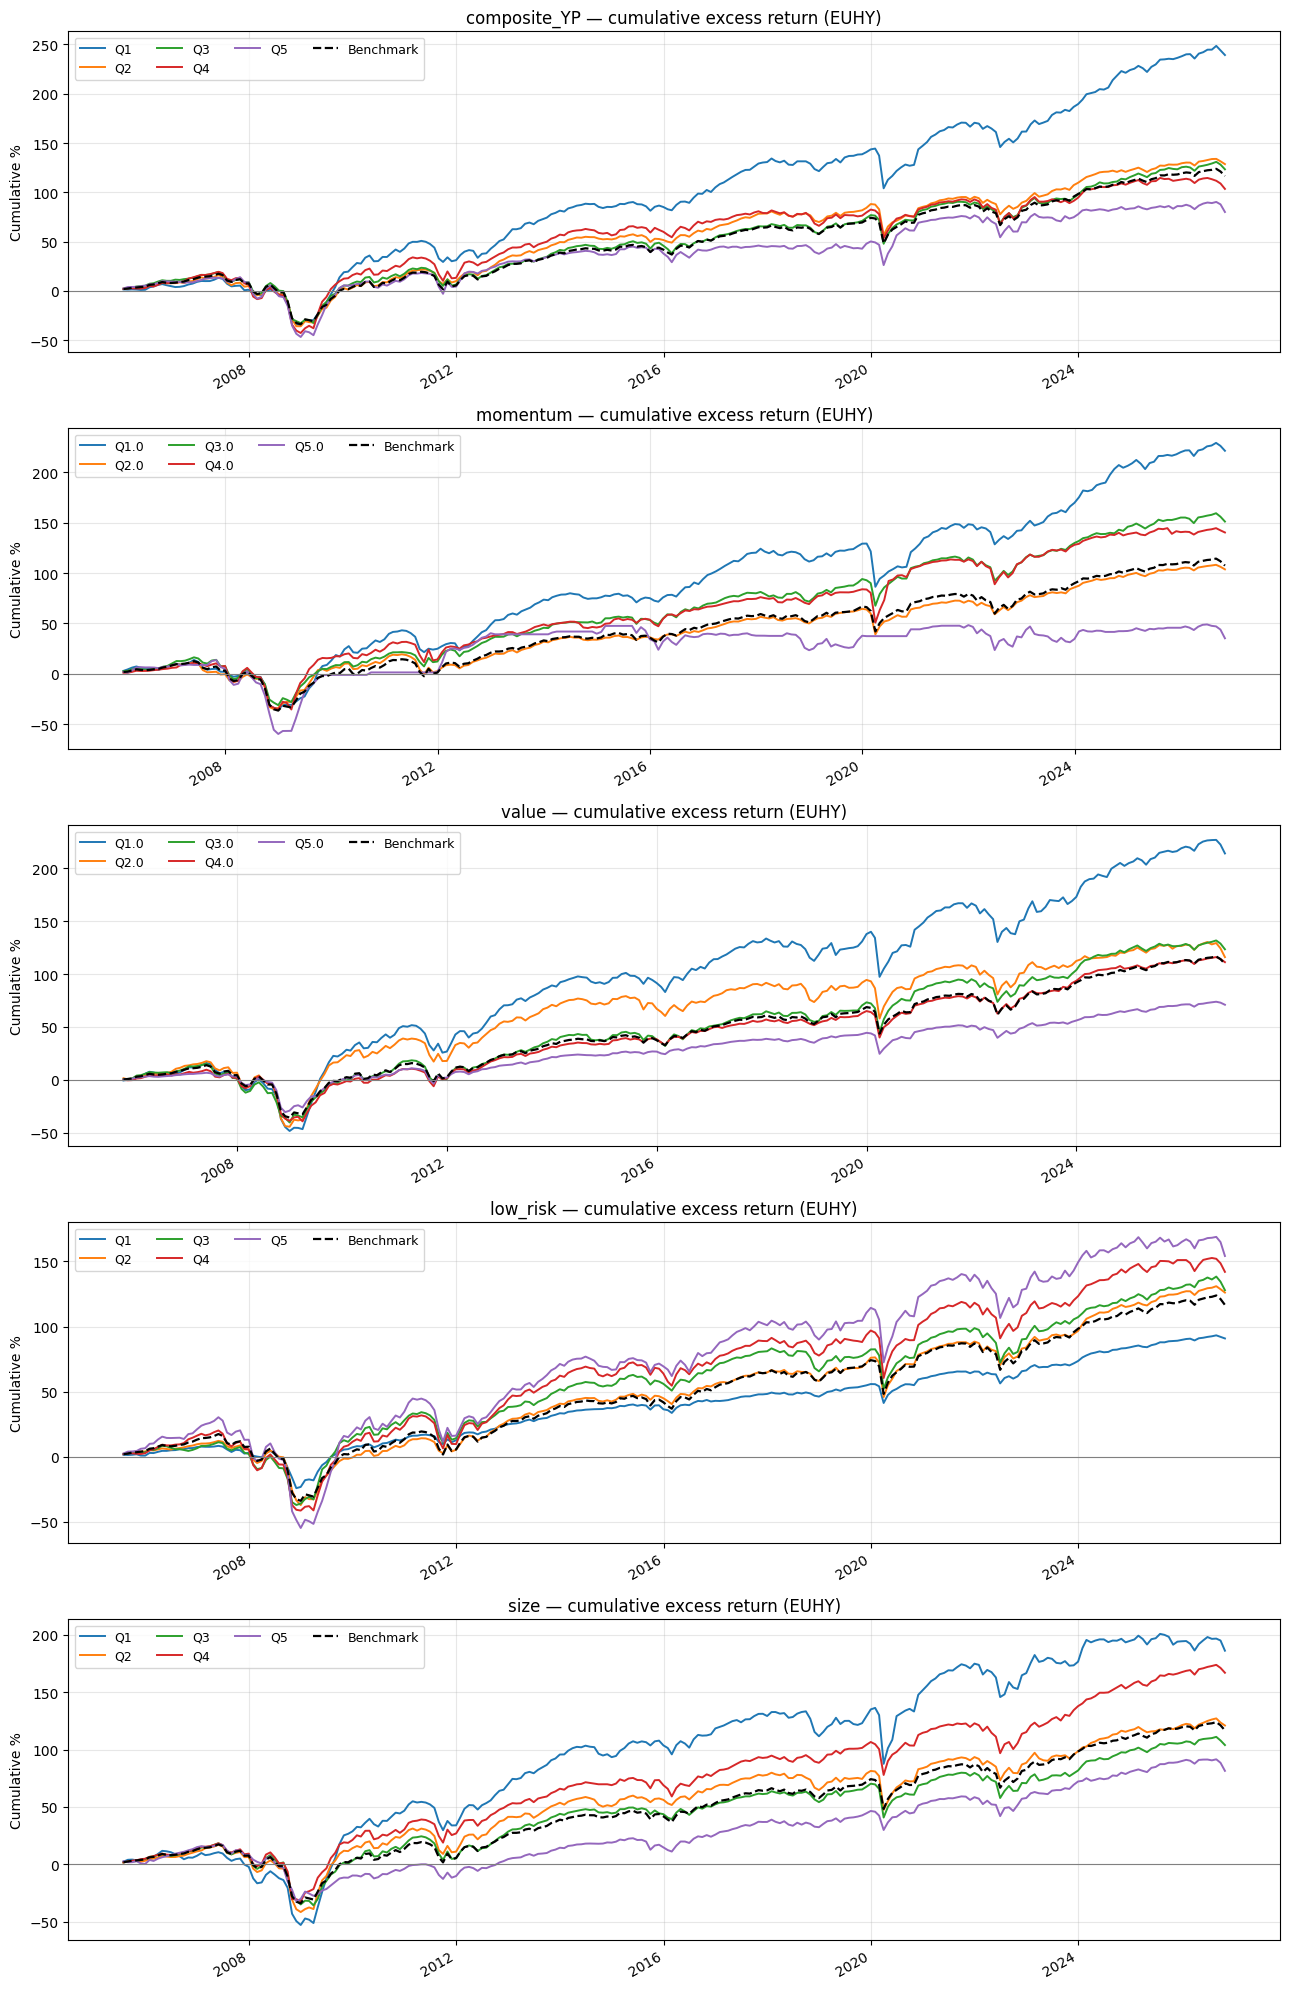

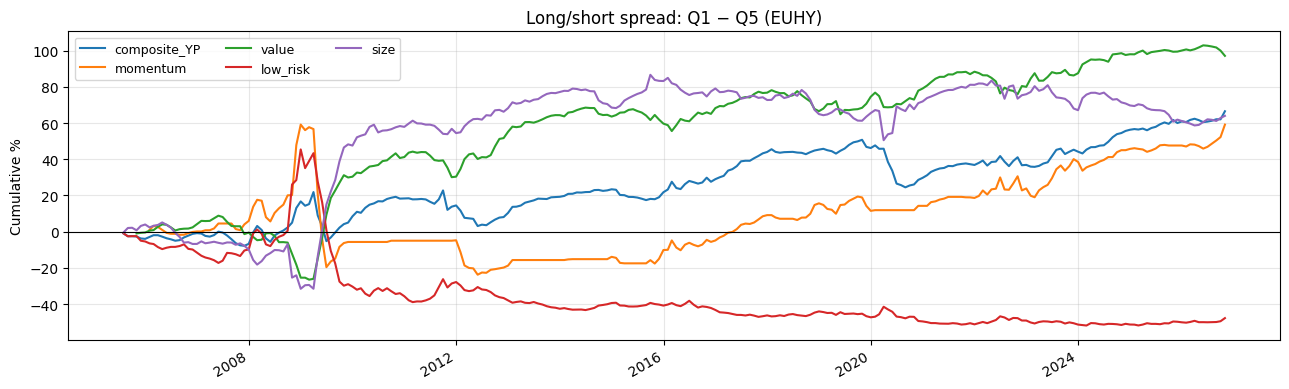

In [56]:
import matplotlib.pyplot as plt

SHOW = [DIAG_SIGNAL] + [f for f in ACTIVE if FACTOR_WEIGHTS.get(f, 0)]
SHOW = [s for s in dict.fromkeys(SHOW) if s in returns_report]

fig, axes = plt.subplots(len(SHOW), 1, figsize=(13, 4 * len(SHOW)), squeeze=False)
for ax, name in zip(axes[:, 0], SHOW):
    pivot = returns_report[name]
    for bucket in [c for c in pivot.columns if c != "Combined"]:
        (1 + pivot[bucket].fillna(0)).cumprod().sub(1).mul(100).plot(
            ax=ax, linewidth=1.4, label=f"Q{bucket}")
    if len(benchmark_report):
        (1 + benchmark_report.reindex(pivot.index).fillna(0)).cumprod().sub(1).mul(100).plot(
            ax=ax, color="black", linestyle="--", linewidth=1.6, label="Benchmark")
    ax.set_title(f"{name} — cumulative excess return ({INDEX_SUFFIX})")
    ax.set_ylabel("Cumulative %")
    ax.axhline(0, color="grey", linewidth=.8)
    ax.grid(alpha=.3)
    ax.legend(ncol=4, fontsize=9)
plt.tight_layout()
plt.show()

# Long/short spread through time
if not long_short.empty:
    fig, ax = plt.subplots(figsize=(13, 4))
    for name in SHOW:
        pivot = returns_report[name]
        if LONG_BUCKET in pivot.columns and SHORT_BUCKET in pivot.columns:
            spread = (pivot[LONG_BUCKET] - pivot[SHORT_BUCKET]).fillna(0)
            (1 + spread).cumprod().sub(1).mul(100).plot(ax=ax, linewidth=1.5, label=name)
    ax.set_title(f"Long/short spread: Q{LONG_BUCKET} − Q{SHORT_BUCKET} ({INDEX_SUFFIX})")
    ax.set_ylabel("Cumulative %")
    ax.axhline(0, color="black", linewidth=.8)
    ax.grid(alpha=.3)
    ax.legend(ncol=3, fontsize=9)
    plt.tight_layout()
    plt.show()

---
# Step 11 — Diagnostic: active sector exposure

The bucket returns tell you *whether* a signal worked. These charts tell you
*what it was actually betting on*.

**Active exposure** = the share of a category inside a bucket minus its share of
the whole universe that month:

$$\text{Active}_{c,q,t} = \%\,\text{of bucket } q \text{ in category } c \;-\; \%\,\text{of the universe in } c$$

A +10% reading means bucket *q* holds ten percentage points more of that sector
than the index does. This is how you find out whether your "value" signal is
quietly a persistent bet on one sector — a common way factor models disappoint
in live trading.

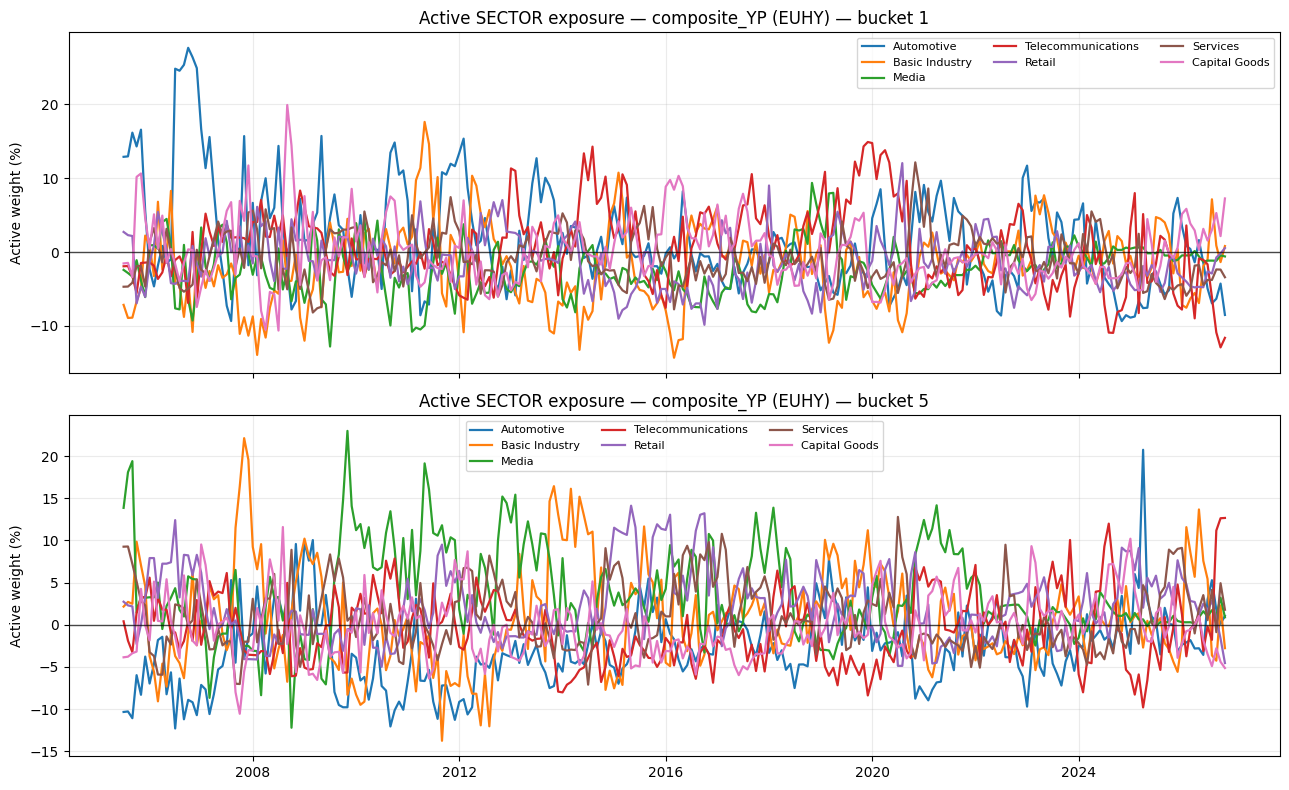

Most-tilted sectors (mean |active weight|):
sector_l3
Automotive            4.78
Basic Industry        4.42
Media                 3.99
Telecommunications    3.80
Retail                3.29
Services              3.02
Capital Goods         2.98


In [57]:
import matplotlib.pyplot as plt


def active_exposure(df, category_col, quintile_col, date_col="date"):
    """% of each bucket in a category, minus that category's universe share."""
    d = df.dropna(subset=[category_col, quintile_col]).copy()
    d[quintile_col] = pd.to_numeric(d[quintile_col], errors="coerce")
    d = d.dropna(subset=[quintile_col])
    d[quintile_col] = d[quintile_col].astype(int)

    # counts per (date, bucket, category) and per (date, bucket)
    wide = d.pivot_table(index=[date_col, quintile_col], columns=category_col,
                         aggfunc="size", fill_value=0)
    totals = wide.sum(axis=1)
    share = wide.div(totals.where(totals > 0), axis=0) * 100        # within bucket

    # universe share that month (all buckets pooled)
    uni = wide.groupby(level=0).sum()
    uni_share = uni.div(uni.sum(axis=1).where(uni.sum(axis=1) > 0), axis=0) * 100

    active = share.subtract(uni_share.reindex(share.index, level=0), fill_value=0)
    return active.sort_index()


def plot_active(active, quintiles, top_n, title, order=None):
    """Chart the most-tilted categories through time, one panel per bucket."""
    quintiles = [q for q in quintiles
                 if q in active.index.get_level_values(1).unique()]
    if not quintiles:
        print("  no data for the requested buckets")
        return
    focus = active[active.index.get_level_values(1).isin(quintiles)]
    ranked = focus.abs().mean().sort_values(ascending=False)
    cols = list(ranked.head(top_n).index)
    if order:
        cols = sorted(cols, key=lambda c: order.index(c) if c in order else 99)

    fig, axes = plt.subplots(len(quintiles), 1, figsize=(13, 4 * len(quintiles)),
                             squeeze=False, sharex=True)
    for ax, q in zip(axes[:, 0], quintiles):
        sub = active[active.index.get_level_values(1) == q]
        sub.index = sub.index.get_level_values(0)
        for c in cols:
            ax.plot(sub.index, sub[c], linewidth=1.6, label=str(c))
        ax.axhline(0, color="black", linewidth=1, alpha=.7)
        ax.set_title(f"{title} — bucket {q}")
        ax.set_ylabel("Active weight (%)")
        ax.grid(alpha=.25)
        ax.legend(ncol=3, fontsize=8)
    plt.tight_layout()
    plt.show()
    return ranked.head(top_n)


diag_qcol = SIGNALS[DIAG_SIGNAL][1]

if "sector_l3" in panel.columns:
    active_sector = active_exposure(panel, "sector_l3", diag_qcol)
    top_sectors = plot_active(
        active_sector, DIAG_QUINTILES, DIAG_TOP_N,
        f"Active SECTOR exposure — {DIAG_SIGNAL} ({INDEX_SUFFIX})")
    print("Most-tilted sectors (mean |active weight|):")
    print(top_sectors.round(2).to_string())
else:
    active_sector = pd.DataFrame()
    print("No 'sector_l3' column — skipping sector diagnostics.")

---
# Step 12 — Diagnostic: active rating exposure

The same calculation across broad rating buckets. This is the one to watch: if
bucket 1 is persistently overweight CCC, the signal is being paid for **taking
credit risk**, not for selecting bonds — and that shows up as a drawdown the
first time spreads gap wider.

Ratings are grouped from notched (`BB1`, `BB2`, `BB3`) to broad (`BB`) and held
in credit order so the legend reads sensibly.

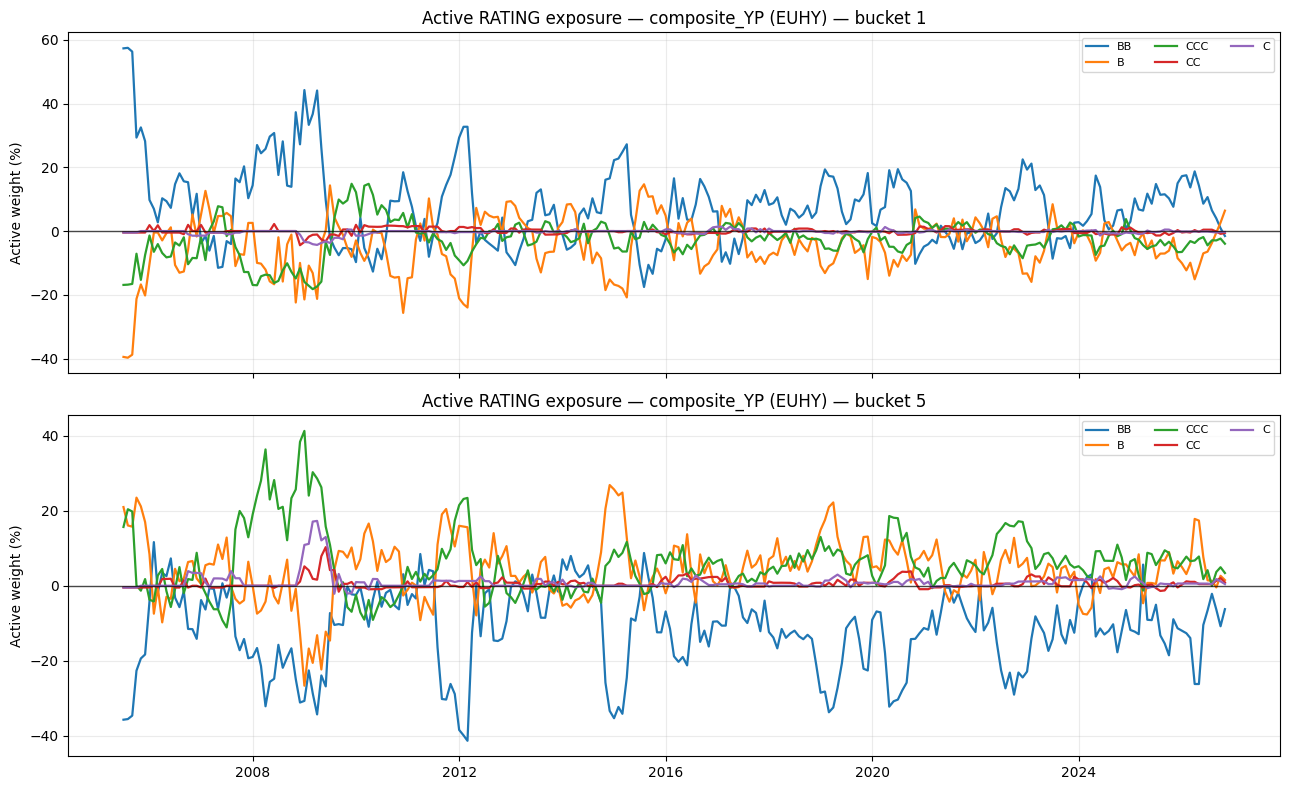

Most-tilted ratings (mean |active weight|):
_broad_rating
BB     11.71
B       7.15
CCC     6.05
CC      0.76
C       0.75

Unmapped rating labels (excluded): ['D']


In [58]:
panel["_broad_rating"] = panel["rating"].map(BROAD_RATING)
present = [r for r in RATING_ORDER if r in set(panel["_broad_rating"].dropna())]

if present:
    active_rating = active_exposure(panel, "_broad_rating", diag_qcol)
    active_rating = active_rating.reindex(
        columns=[c for c in RATING_ORDER if c in active_rating.columns])
    top_ratings = plot_active(
        active_rating, DIAG_QUINTILES, DIAG_TOP_N,
        f"Active RATING exposure — {DIAG_SIGNAL} ({INDEX_SUFFIX})",
        order=RATING_ORDER)
    print("Most-tilted ratings (mean |active weight|):")
    print(top_ratings.round(2).to_string())

    unmapped = panel.loc[panel["_broad_rating"].isna(), "rating"].unique()
    if len(unmapped):
        print(f"\nUnmapped rating labels (excluded): {list(unmapped)[:10]}")
else:
    active_rating = pd.DataFrame()
    print("No mappable ratings — skipping rating diagnostics.")

---
# Step 13 — Export historical screens

A **separate** workbook holding the month-by-month bond-level screen: one sheet
per month, every bond with its factor ranks and percentiles. This is the file a
PM actually reads to see *which bonds* the model likes.

Percentile ranks are 0–100 where **0 = most attractive**, matching the rank
convention used throughout (lower is better).

The column list is built **generically from whichever factors are active**, so a
new factor appears in the screen automatically.

> **File size.** One sheet per month over the full history is ~250 sheets and
> can take several minutes to write. `SCREEN_LAST_N_MONTHS` caps it (default 24).
> Set it to `None` for the complete history, or set `EXPORT_DATES` to a specific
> list of month-ends.

In [59]:
def clean_sheet_name(name: str) -> str:
    for ch in ["\\", "/", "*", "?", ":", "[", "]"]:
        name = name.replace(ch, "")
    return name[:31]

#SCREEN_LAST_N_MONTHS = 255                 # None = every month (large file!)
if EXPORT_SCREENS:
    screen = panel.copy()

    # Percentile rank (0-100, 0 = best) for every signal, computed within month.
    pct_cols = []
    for name, (rank_col, _) in SIGNALS.items():
        col = f"pct_{name}"
        screen[col] = (screen.groupby("date")[rank_col].rank(pct=True) * 100
                       ).round(0).astype("Int64")
        pct_cols.append(col)

    # Build the column list generically: identifiers, then signals, then analytics.
    id_cols = [c for c in ["bond_id", "cusip", "description", "issuer", "rating",
                           "maturity_date", "currency",
                           "sector_l1", "sector_l2", "sector_l3", "sector_l4"]
               if c in screen.columns]
    factor_cols = [c for f in ACTIVE for c in (f"{f}_rank", f"{f}_quintile")
                   if c in screen.columns]
    signal_cols = [c for c in ["composite_rank", "composite_quintile", "composite_YP_rank", "composite_YP_quintile"] if c in screen.columns]
    market_cols = [c for c in ["price", "oas", "ytw", "ytm", "mkt_weight",
                               "excess_return", "maturity_years",
                               "mod_dur_worst", "eff_dur", "eff_convexity"] if c in screen.columns]
    screen_cols = id_cols + pct_cols + signal_cols + factor_cols + market_cols + ["date"]

    # Which months to write.
    if EXPORT_DATES is not None:
        dates_out = sorted(pd.to_datetime(pd.Series(EXPORT_DATES)))
    else:
        dates_out = sorted(d for d in screen["date"].unique()
                           if pd.Timestamp(d) > CUTOFF_DATE)
    if SCREEN_LAST_N_MONTHS:
        dates_out = dates_out[-SCREEN_LAST_N_MONTHS:]

    screens_path = Path(OUTPUT_DIR) / f"{INDEX_SUFFIX} Ranks {datetime.now():%Y%m%d}.xlsx"
    written = 0
    with pd.ExcelWriter(screens_path, engine="openpyxl") as xl:
        for d in dates_out:
            sub = screen[screen["date"] == d]
            if sub.empty:
                continue
            (sub.reindex(columns=screen_cols)
                .sort_values("pct_composite" if "pct_composite" in screen_cols else "date")
                .to_excel(xl, sheet_name=clean_sheet_name(pd.Timestamp(d).strftime("%Y-%m-%d")),
                          index=False))
            written += 1
        if written == 0:
            pd.DataFrame({"Message": [f"No data after cutoff {CUTOFF_DATE:%Y-%m-%d}"]}) \
                .to_excel(xl, sheet_name="No Data", index=False)

    print(f"Saved: {screens_path}")
    print(f"  {written} monthly sheet(s), {len(screen_cols)} columns each")
    print(f"  months: {pd.Timestamp(dates_out[0]):%Y-%m} → "
          f"{pd.Timestamp(dates_out[-1]):%Y-%m}" if dates_out else "  (none)")
    print(f"  sorted best-first by pct_composite (0 = most attractive)")
else:
    screens_path = None
    print("EXPORT_SCREENS = False — skipped.")

Saved: Output\EUHY Ranks 20261102.xlsx
  2 monthly sheet(s), 41 columns each
  months: 2026-09 → 2026-10
  sorted best-first by pct_composite (0 = most attractive)


---
# Step 14 — Run summary

A short reconciliation of what was actually run, plus the caveats that belong
next to any result from this notebook.

In [60]:
print("=" * 74)
print(f"RUN SUMMARY — {INDEX_SUFFIX}")
print("=" * 74)
print(f"Data      : {panel['date'].nunique()} months, {len(panel):,} rows, "
      f"{panel['bond_id'].nunique():,} bonds")
print(f"Period    : {panel['date'].min():%Y-%m-%d} → {panel['date'].max():%Y-%m-%d}")
print(f"Weights   : { {k: round(v,4) for k,v in FACTOR_WEIGHTS.items() if v} }")
print(f"Output    : {out_path}")
if EXPORT_SCREENS and screens_path:
    print(f"Screens   : {screens_path}")

if not ic_summary.empty:
    best = ic_summary.loc[ic_summary["T-Stat"].abs().idxmax()]
    print(f"\nStrongest signal by |t| : {best['Signal']} "
          f"(mean IC {best['Mean IC']:+.4f}, t = {best['T-Stat']:+.2f})")

print("""
CAVEATS — read before quoting any of these numbers
--------------------------------------------------
1. Quintile baskets are a SIGNAL-QUALITY TEST, not an investable portfolio.
   No duration or spread-duration matching, no sector neutrality, no position
   limits, and NO TRANSACTION COSTS. Monthly rebalancing across a full index
   implies material turnover — see the Turnover column in Analytics.
2. Equal-weighted baskets against a cap-weighted benchmark are not like-for-like.
   Equal weighting carries a small-issuer tilt that overlaps the Size factor.
   Set PORTFOLIO_WEIGHTING = 'mktcap' for a cleaner comparison.
""")

RUN SUMMARY — EUHY
Data      : 257 months, 119,228 rows, 3,210 bonds
Period    : 2005-06-30 → 2026-10-31
Weights   : {'momentum': 0.25, 'value': 0.25, 'low_risk': 0.25, 'size': 0.25}
Output    : Output\FI_factor_EUHY_20261102.xlsx
Screens   : Output\EUHY Ranks 20261102.xlsx

Strongest signal by |t| : composite (mean IC -0.0299, t = -4.13)

CAVEATS — read before quoting any of these numbers
--------------------------------------------------
1. Quintile baskets are a SIGNAL-QUALITY TEST, not an investable portfolio.
   No duration or spread-duration matching, no sector neutrality, no position
   limits, and NO TRANSACTION COSTS. Monthly rebalancing across a full index
   implies material turnover — see the Turnover column in Analytics.
2. Equal-weighted baskets against a cap-weighted benchmark are not like-for-like.
   Equal weighting carries a small-issuer tilt that overlaps the Size factor.
   Set PORTFOLIO_WEIGHTING = 'mktcap' for a cleaner comparison.



---
# Appendix — Adding a new factor

Three steps, no changes anywhere else.

**1. Write the scoring function.** It takes the panel and returns one number per
row. Only use information available at that row's `date`.

```python
def factor_carry(df):
    return df["ytw"]          # yield to worst
```

**2. Register it** in the `FACTORS` dict (Step 4):

```python
FACTORS["carry"] = dict(
    func=factor_carry,
    higher_is_better=True,      # more yield = more attractive
    fill="group_median",
    is_rank=False,
    label="Yield to worst",
)
```

**3. Give it a weight** in Step 0:

```python
FACTOR_WEIGHTS = {"momentum": .25, "value": .25, "low_risk": .25, "carry": .25}
```

Re-run. Ranking, bucketing, the composite, the backtest, the analytics, the
charts and the Excel export all pick it up automatically.

### Avoiding look-ahead bias

The one rule that matters: a factor at date *t* may only use data known at *t*.
Note how Momentum uses `.shift(1)` before its rolling window so the current
month never contributes to its own signal. If you use a rolling window, lag it.

### Debugging a single date

To inspect the value regression for one month:

```python
d = panel[panel["date"] == pd.Timestamp("2020-06-30")].copy()
d["_oas_chg"] = 0.0
dev = cross_sectional_oas_regression(d, ["maturity_years", "_oas_chg"],
                                     ["rating", "sector_l3"])
dev.describe()
```